Namespaces : -
A namespace is a space that holds names(identifiers).Programmatically speaking, namespaces are dictionary of identifiers(keys) and their objects(values)

There are 4 types of namespaces:

    1) Builtin Namespace
    2) Global Namespace
    3) Enclosing Namespace
    4) Local Namespace


In [ ]:
def add(x, y):
    print(x+y)

a = 2
b = 3
add(2, 3)

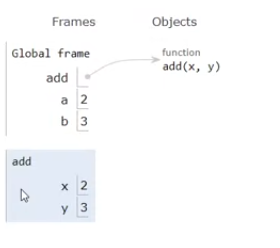

There are two namespaces for the above code.
add in the above also acts as a variable name. 

LEGB rule: -
The interpreter searches for a name from the inside out, looking in the local, enclosing, global, and finally the built-in scope. If the interpreter doesn’t find the name in any of these locations, then Python raises a NameError exception.

In [2]:
#local and global:-
a = 2   #global variable

def temp():
    a = 3
    print(a)        #local variable

temp()
print(a)

3
2


In [ ]:
#local and global -> local does not have but global has
a = 2   #global variable

def temp():
    print(a)        #local variable

temp()
print(a)

#Here first interpreter checks in local, as not there in local, hence it follows the LEGB rule after some checks it checks global and prints the global variable a.

2
2


In [ ]:
#editing global from local: -
a = 2   

def temp():
    a+=1
    print(a)      

temp()
print(a)

#This gives an UnboundlocalError. We can only read global variables from local scope, but we cannot write global variables from local scope. This gives error.


UnboundLocalError: cannot access local variable 'a' where it is not associated with a value

In [ ]:
#But to change global variable from local scope.
a = 2   

def temp():
    global a        #By this we can use global a to change the value. We can also write using global a.
    a+=1
    print(a)      

temp()
print(a)


3
3


In [ ]:
#gloal created inside local: -
def temp():
    global a 
    a = 1

temp()
print(a)

#Here a is made in global as we can access it outside the local scope.

1


In [ ]:
#function parameter is local
def temp(z):
    print(z)

a = 5
temp(5)
print(a)

#Here z is a local variable as it is created in the scope of temp() function. 
#A function parameter is always a local variable.

5
5


Built-in scope: -

In [ ]:
#built-in
#type(), int(), print(), str(), len(), min() etc are built-in scope functions

import builtins
print(dir(builtins))

#The following all functions are built-ins.

['ArithmeticError', 'AssertionError', 'AttributeError', 'BaseException', 'BaseExceptionGroup', 'BlockingIOError', 'BrokenPipeError', 'BufferError', 'BytesWarning', 'ChildProcessError', 'ConnectionAbortedError', 'ConnectionError', 'ConnectionRefusedError', 'ConnectionResetError', 'DeprecationWarning', 'EOFError', 'Ellipsis', 'EncodingWarning', 'EnvironmentError', 'Exception', 'ExceptionGroup', 'False', 'FileExistsError', 'FileNotFoundError', 'FloatingPointError', 'FutureWarning', 'GeneratorExit', 'IOError', 'ImportError', 'ImportWarning', 'IndentationError', 'IndexError', 'InterruptedError', 'IsADirectoryError', 'KeyError', 'KeyboardInterrupt', 'LookupError', 'MemoryError', 'ModuleNotFoundError', 'NameError', 'None', 'NotADirectoryError', 'NotImplemented', 'NotImplementedError', 'OSError', 'OverflowError', 'PendingDeprecationWarning', 'PermissionError', 'ProcessLookupError', 'PythonFinalizationError', 'RecursionError', 'ReferenceError', 'ResourceWarning', 'RuntimeError', 'RuntimeWarning

In [5]:
#Renaming built-in 
L = [1, 2, 3]

def max():
    print("Hello")

max(L)      #Gives error as our max function is global so global is given first pref than built-in.

TypeError: max() takes 0 positional arguments but 1 was given

Enclosing scope: -
Can be seen in nested function

In [ ]:
def outer():
    def inner():
        print("Inner func")
    inner()
    print("Outer func")

outer()
print("Main function")

#Here all three scopes exist at a point of time
#Here main function is global, inner() function is local and the outer() function is enclosing.

Inner func
Outer func
Main function


In [ ]:
#enclosing scope:-
def outer():
    a=3
    def inner():
        a=4
        print(a)
    inner()
a = 1
outer()
print("Main program")

#Local is first pref, hence interpreter first searches a in local -> enclosing -> global -> built-in

4
Main program


In [ ]:
def outer():
    a=3
    def inner():
        print(a)
    inner()
a = 1
outer()
print("Main program")

#Here as local not found, hence it will search in enclosing(outer func)

3
Main program


In [ ]:
def outer():
    def inner():
        print(a)
    inner()
a = 1
outer()
print("Main program")

#Here no local and enclosing found, hence it will take from global.

1
Main program


In [ ]:
#changing enclosing value from inner: -
def outer():
    a = 1
    def inner():
        nonlocal a
        a+=1
        print(f"Inner a: {a}")
    inner()
    print(f"Outer a: {a}")

outer()

#Here nonlocal is used to change value in enclosing scope from local scope.

Inner a: 2
Outer a: 2


Decorators: -
A decorator in python is a function that receives another function as input and adds some functionality(decoration) to and it and returns it.
It adds functionality to the function which it got as input.

This can happen only because python functions are 1st class citizens.(1st class citizens are those objects in a programming language with which we can do any operation we want.)

There are 2 types of decorators available in python
1) Built in decorators. Ex: @staticmethod, @classmethod, @abstractmethod and @property etc
2) User defined decorators that programmers can create according to need.


In [ ]:
#Python functions are first class citizens.
def func():
    print('Hello')

a = func()      #Here we renamed the function as a
func() 
del func #We can delete the function

In [ ]:
#This is decorator
def modify(func, num):          #Here we passed a function as a parameter to another function as input.
    return func(num)

#This is input
def square(num):
    return num**2

print(modify(square, 2))

4


In [ ]:
#Example: -     (This is a basic example.)
def my_dec(func):
    def wrapper():
        print("***************************")
        func()
        print("***************************")
    return wrapper

def hello():
    print("Hello")

def display():
    print("This is decorator example")

a = my_dec(hello)       #Here a is wrapper
a()

b = my_dec(display)
b()

***************************
Hello
***************************
***************************
This is decorator example
***************************


In [ ]:
def outer():
    a = 5
    def inner():
        print(a)
    return inner

b = outer()
b()

#The above program prints 5.
#Even after the parent function is removed from the memory, the inner function which is in the memory can access the attributes of the outer function. This is called closure. (Imp concept)

5


In [ ]:
#Better syntax: -
def my_dec(func):
    def wrapper():
        print("***************************")
        func()
        print("***************************")
    return wrapper

@my_dec         # @our_decorator_name
def hello():
    print("Hello")

hello()     #This directly dies the work of the two lines.

***************************
Hello
***************************


In [ ]:
#Meaningful decorator: -
#This decorator will print the execution time of any function.
import time

def exec_time(func):
    def wrapper():
        start = time.time()
        func()
        end = time.time()
        print(f"Time taken by {func.__name__} is {end - start} seconds")
    return wrapper

@exec_time
def hello():
    print("Hello world")
    time.sleep(2)       #This makes the function delay by 2secs

hello()

Hello world
Time taken by hello is 2.0001518726348877 seconds


In [ ]:
#problem with this: -
import time

def exec_time(func):
    def wrapper():
        start = time.time()
        func()      #No params function
        end = time.time()
        print(f"Time taken by {func.__name__} is {end - start} seconds")
    return wrapper

@exec_time
def square(num):
    time.sleep(2)
    return num**2

square(2)

#This gives an error becaue the thing we are executing is the wrapper and in the wrapper we are taking no params

TypeError: exec_time.<locals>.wrapper() takes 0 positional arguments but 1 was given

In [ ]:
#TO make the above code generic
import time

def exec_time(func):
    def wrapper(*args):         #Now it will run for any number of arguments.
        start = time.time()
        func(*args)      
        end = time.time()
        print(f"Time taken by {func.__name__} is {end - start} seconds")
    return wrapper

@exec_time
def square(num):
    time.sleep(2)
    print(num**2)

@exec_time
def hello():
    print("Hello")

square(2)
hello()

#Now this will work

4
Time taken by square is 2.0002012252807617 seconds
Hello
Time taken by hello is 1.0728836059570312e-05 seconds


In [ ]:
#A complex example: -   (This involves 2 wrappers)
#We are making a decorator which checks whether the input we got in for the function is of correct datatype or not

def check_data_type(data_type):
    def outer_wrapper(func):
        def inner_wrapper(*args):
            if isinstance(*args, data_type):      #as args is a tuple, we are removing the first index which determines the tupe of our argument.
                func(*args)
            else:
                raise TypeError("Not the valid datatype we want for the function.")
        return inner_wrapper
    return outer_wrapper

@check_data_type(int)
def square(n):
    print(n**2)

@check_data_type(str)
def greet(name):
    print(f"Hello {name}")

square(2)
greet("Nikhil")
greet(4)

4
Hello Nikhil


TypeError: Not the valid datatype we want for the function.